# H15 Part A · Step 2 · The side-car and its loss

The review of **step 2** of [the plan](../../../docs/drivejepa-perception-sidecar-A.md) (§4–5). It opens the
model (`gallops.drivejepa_perception.sidecar`) part by part and builds its loss by hand, then checks every
number against the code that trains:

1. the model, part by part, and the three variants;
2. where the queries start;
3. Hungarian matching, worked on a toy example;
4. each term of the loss on the toy, checked against `SideCarLoss`;
5. the loss on a real batch, before any training;
6. a short fit: does every term go down?
7. a primer on the loss options, and how each shapes the gradient (with references);
8. does this model have a mode-collapse problem?
9. weighting what matters: the loss-side options.

**Kernel:** `drive-jepa-v2` ("Drive-JEPA v2") at this site: it starts the interpreter `gallops.toml` names as `[python] drivejepa` (Python 3.9, torch 2.1), the one these outputs came from. Not `python3` ("Python 3 (ipykernel)"), which starts the system Python without torch, and not `drive-jepa-py39`, another venv with another navsim tree first on its path. Elsewhere, any kernel that starts `[python] drivejepa`. Headless: `scripts/run_notebooks.py`. It runs on the CPU and reads only the caches.

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "gallops").is_dir())
sys.path.insert(0, str(REPO / "src"))
os.environ.setdefault("GALLOPS_CONFIG", str(REPO / "gallops.toml"))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.patches import Polygon
from matplotlib.ticker import FuncFormatter
from scipy.optimize import linear_sum_assignment

from gallops.config import SiteConfig
from gallops.drivejepa_perception import navsim_data, sidecar, train_sidecar, views
from gallops.drivejepa_perception import targets as tg

views.use_style()
pd.set_option("display.precision", 3)
torch.set_num_threads(16)
cfg = SiteConfig.load()
RUNS = Path(cfg.resolve("{runs}")) / "drivejepa_perception"
labels = dict(np.load(RUNS / "labels-v1" / "labels.npz"))
logs = json.loads((RUNS / "labels-v1" / "manifest.json").read_text())["logs"]
token_logs = np.array([logs[i] for i in labels["log_id"]])
splits = json.loads((REPO / "recipes" / "drivejepa_perception" / "splits.json").read_text())
rows = {s: np.flatnonzero(np.isin(token_logs, splits[s])) for s in ("train", "select", "report")}
proj = tg.front_projection(np.asarray(np.load(RUNS / "tokens-v1" / "lidar2img.npy", mmap_mode="r"))).astype(np.float32)
vit = np.load(RUNS / "tokens-vit-v1" / "vit_out.npy", mmap_mode="r")  # (103,288, 512, 1024) fp16
print("ViT-out cache:", vit.shape, vit.dtype)


def targets_of(row):
    return tg.build(navsim_data.agents_of(labels, row), proj[row])


def batch_of(picked):
    """The trainer's batch for these rows (train_sidecar.Rows, collated), on the CPU in fp32."""
    items = [train_sidecar.Rows(vit, int, picked, proj, {r: targets_of(r) for r in picked})[i] for i in range(len(picked))]
    batch = torch.utils.data.default_collate(items)
    batch["tokens"] = batch["tokens"].float()
    return batch


def y_axis_left(ax):
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{-v:g}"))
    ax.set_xlabel("y (m): + left, − right")
    ax.set_ylabel("x (m), forward")

ViT-out cache: (103288, 512, 1024) float16


## 1. The model, part by part

The side-car reads two things per sample: the ViT's output, **512 tokens × 1024**, and CAM_F0's 4×4
projection (ego → the 512×256 token image). Everything below is v1, the first pass's A1 side-car, built
exactly as the trainer builds it (`train_sidecar.build_model`, seed 0).

In [2]:
torch.manual_seed(0)
v1 = train_sidecar.build_model({"tap": "vit_out", **train_sidecar.VARIANTS["v1"]})


def count(module):
    return sum(p.numel() for p in module.parameters())


layer = v1.layers[0]
parts = {
    "input projection: Linear 1024 → 256 + LayerNorm": count(v1.proj) + count(v1.ln_tok),
    "token rays: MLP 48 → 256 → 256": count(v1.ray_mlp),
    "query position: MLP 3 → 256 → 256": count(v1.pos_mlp),
    "64 queries (256) + 64 reference points (3)": v1.query.numel() + v1.ref.numel(),
    "per layer · self-attention (q, k, v, out)": count(layer.sa),
    "per layer · cross-attention (q, k, v, out)": count(layer.ca),
    "per layer · FFN 256 → 1024 → 256": count(layer.ffn),
    "per layer · 3 LayerNorms": count(layer.ln_sa) + count(layer.ln_ca) + count(layer.ln_ff),
    "per layer · heads (class 4, Δcentre 3, box 5, velocity 2, path 4)": count(layer.cls_head)
    + count(layer.ref_mlp) + count(layer.box_head) + count(layer.vel_head) + count(layer.path_head),
}
table = pd.Series(parts, name="parameters").to_frame()
table["per model (3 layers)"] = [v if not k.startswith("per layer") else 3 * v for k, v in parts.items()]
print(f"v1: {count(v1):,} parameters")
table

v1: 4,388,342 parameters


,parameters,per model (3 layers)
input projection: Linear 1024 → 256 + LayerNorm,262912,262912
token rays: MLP 48 → 256 → 256,78336,78336
query position: MLP 3 → 256 → 256,66816,66816
64 queries (256) + 64 reference points (3),16576,16576
"per layer · self-attention (q, k, v, out)",263168,789504
"per layer · cross-attention (q, k, v, out)",263168,789504
per layer · FFN 256 → 1024 → 256,525568,1576704
per layer · 3 LayerNorms,1536,4608
"per layer · heads (class 4, Δcentre 3, box 5, velocity 2, path 4)",267794,803382


In [3]:
INFERENCE_PATH = 307_860_553  # the released model's inference path (H15 plan, §2)
rows_v = []
for name, arch in train_sidecar.VARIANTS.items():
    model = train_sidecar.build_model({"tap": "vit_out", **arch})
    rows_v.append({"variant": name, **arch, "parameters (M)": count(model) / 1e6,
                   "share of the inference path": count(model) / INFERENCE_PATH})
pd.DataFrame(rows_v).set_index("variant")

,d_model,heads,ffn,layers,queries,parameters (M),share of the inference path
variant,,,,,,,
v1,256,8,1024,3,64,4.388,0.014
v2,256,8,1024,6,128,8.369,0.027
v3,384,12,1536,6,128,18.444,0.060


**What comes out.** One dictionary per decoder layer; every layer is supervised, only the last is read.
A forward of four real train samples:

In [4]:
picked = np.random.default_rng(0).choice(rows["train"], 4, replace=False)
batch4 = batch_of(picked)
v1.eval()
with torch.no_grad():
    outs = v1(batch4["tokens"], batch4["projection"])
pd.DataFrame(
    {k: [tuple(o[k].shape) for o in outs] for k in ("logits", "box", "vel", "path")},
    index=[f"layer {i}" for i in range(len(outs))],
)

,logits,box,vel,path
layer 0,"(4, 64, 4)","(4, 64, 8)","(4, 64, 2)","(4, 64, 2, 2)"
layer 1,"(4, 64, 4)","(4, 64, 8)","(4, 64, 2)","(4, 64, 2, 2)"
layer 2,"(4, 64, 4)","(4, 64, 8)","(4, 64, 2)","(4, 64, 2, 2)"


- `logits` (B, 64, 4): vehicle, pedestrian, cyclist, none.
- `box` (B, 64, 8): centre x, y, z (m, ego frame) = reference point + Δcentre; then log l, log w, log h,
  sin yaw, cos yaw.
- `vel` (B, 64, 2): vx, vy (m/s, the ego's axes; ground velocity).
- `path` (B, 64, 2, 2): offsets from the slot's own centre at +0.5 s and +1.0 s.

## 2. Where the queries start

Each of the 64 queries has a learned **reference point**, its first guess of where its agent is. They start
uniform over x 2–50 m, |y| < 30 m, z 0 (`SideCar.__init__`, seeded by the run's seed). Below: v1's start at
seed 0 against the camera's view and against where train targets actually are. A point outside the view
can still find an agent (its first layer's Δcentre is unbounded), but it starts with no prior.

v1: 32 of 64 reference points start inside the camera's view (50%)
v2: 65 of 128 reference points start inside the camera's view (51%)


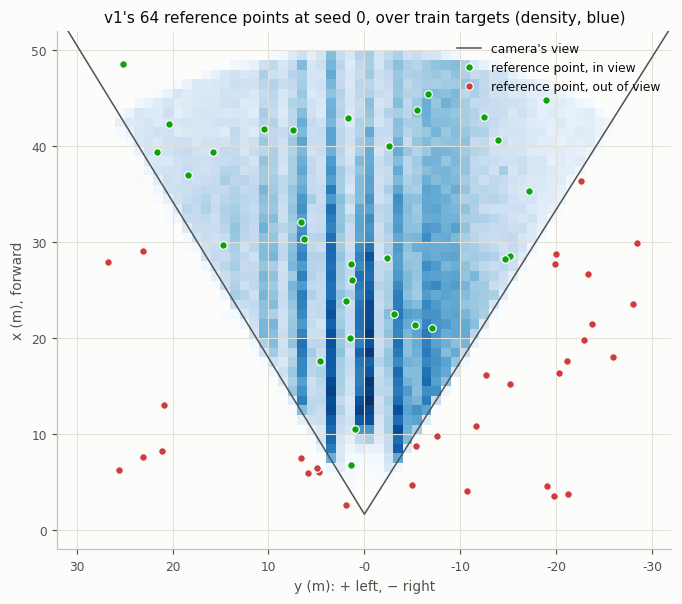

In [5]:
row0 = int(rows["select"][0])
for name in ("v1", "v2"):
    torch.manual_seed(0)
    model = train_sidecar.build_model({"tap": "vit_out", **train_sidecar.VARIANTS[name]})
    ref = model.ref.detach().numpy().astype(np.float64)
    inside = tg.seen(proj[row0].astype(np.float64), ref)
    print(f"{name}: {int(inside.sum())} of {len(ref)} reference points start inside the camera's view "
          f"({inside.mean():.0%})")

torch.manual_seed(0)
ref = v1.ref.detach().numpy()
sample = np.random.default_rng(1).choice(rows["train"], 20000, replace=False)
xy = np.concatenate([(lambda t: t["box"][t["mask"], :2])(targets_of(r)) for r in sample])
fig, ax = plt.subplots(figsize=(7.2, 6.2))
ax.hist2d(-xy[:, 1], xy[:, 0], bins=[np.linspace(-32, 32, 65), np.linspace(-2, 52, 55)], cmap="Blues", cmin=1)
edges = views.view_edges(proj[row0], reach=60)
ax.plot(-edges[[1, 0, 2], 1], edges[[1, 0, 2], 0], color=views.INK_2, lw=1.0, label="camera's view")
inside = tg.seen(proj[row0].astype(np.float64), ref.astype(np.float64))
ax.plot(-ref[inside, 1], ref[inside, 0], "o", ms=5, color=views.HIT, mec=views.SURFACE, mew=0.8, label="reference point, in view")
ax.plot(-ref[~inside, 1], ref[~inside, 0], "o", ms=5, color=views.MISS, mec=views.SURFACE, mew=0.8, label="reference point, out of view")
ax.set_xlim(-32, 32)
ax.set_ylim(-2, 52)
ax.set_aspect("equal")
y_axis_left(ax)
ax.legend(loc="upper right")
ax.set_title("v1's 64 reference points at seed 0, over train targets (density, blue)")
plt.show()

## 3. Hungarian matching, by hand

Before any loss, each sample's targets are paired one-to-one with slots (DETR's set matching), separately
for every decoder layer. The cost of giving slot *q* to target *g*:

$$C_{qg} = 2 \cdot \big(-p_q(\text{class of } g)\big) + 0.25 \cdot \lVert c_q - c_g \rVert_1$$

with $p_q$ the slot's softmax over the four classes and $c$ the 3D centre in metres. `scipy`'s
`linear_sum_assignment` finds the pairing with the least total cost; every target gets a slot, the other
slots become "none".

**The toy:** two targets (a vehicle 12 m ahead, a pedestrian 8 m ahead and 3 m to the right) and five
slots. Slot 0 sits on the vehicle but thinks "pedestrian"; slot 1 is 2 m off but sure of "vehicle".

In [6]:
NONE = tg.NONE
toy_logits = torch.tensor([[[0.0, 2.5, 0.0, 1.0],   # slot 0: on the vehicle, says pedestrian
                            [3.0, 0.0, 0.0, 0.5],   # slot 1: 2 m off the vehicle, says vehicle
                            [0.0, 2.0, 0.0, 0.5],   # slot 2: near the pedestrian, says pedestrian
                            [0.0, 0.0, 0.0, 3.0],   # slot 3: far away, says none
                            [1.0, 1.0, 0.0, 1.0]]])  # slot 4: undecided, 20 m away
toy_centres = torch.tensor([[[12.0, 0.0, 0.8], [14.0, 0.0, 0.8], [8.5, -3.0, 0.9], [40.0, 10.0, 0.0], [30.0, 0.0, 0.0]]])
toy_box = torch.zeros(1, 5, 8)
toy_box[..., :3] = toy_centres
toy_out = {"logits": toy_logits, "box": toy_box, "vel": torch.zeros(1, 5, 2), "path": torch.zeros(1, 5, 2, 2)}

toy_t = {k: torch.from_numpy(v)[None] for k, v in tg.build(
    {
        "cls": np.array([0, 1], np.int8),
        "box": np.array([[12.0, 0.0, 0.8, 4.5, 1.9, 1.6, 0.1], [8.0, -3.0, 0.9, 0.7, 0.7, 1.8, 1.6]], np.float32),
        "velocity": np.array([[5.0, 0.2], [0.0, 1.2]], np.float32),
        "path": np.array([[[14.5, 0.3], [17.0, 0.4]], [[8.0, -2.4], [np.nan, np.nan]]], np.float32),
        "path_ok": np.array([[True, True], [True, False]]),
    },
    np.diag([1.0, 1.0, 1.0, 1.0]) @ np.array([[256, -400, 0, 0], [128, 0, -400, 600], [1, 0, 0, 0], [0, 0, 0, 1.0]]),
).items()}
print("targets (nearest first):", [views.CLASS_NAMES[c] for c in toy_t["cls"][0][toy_t["mask"][0]].tolist()])

p = toy_logits.softmax(-1)[0]
cls_t = toy_t["cls"][0][toy_t["mask"][0]]
ctr_t = toy_t["box"][0][toy_t["mask"][0], :3]
class_cost = -2.0 * p[:, cls_t]
centre_cost = 0.25 * torch.cdist(toy_centres[0], ctr_t, p=1)
total = class_cost + centre_cost
names = [f"target {j}: {views.CLASS_NAMES[c]}" for j, c in enumerate(cls_t.tolist())]
cost_table = pd.concat(
    {"−2 · p(class)": pd.DataFrame(class_cost.numpy(), columns=names),
     "0.25 · L1 centre": pd.DataFrame(centre_cost.numpy(), columns=names),
     "total": pd.DataFrame(total.numpy(), columns=names)}, axis=1)
cost_table.index = [f"slot {q}" for q in range(5)]
cost_table

targets (nearest first): ['pedestrian', 'vehicle']


−2 · p(class)                       0.25 · L1 centre  \
       target 0: pedestrian target 1: vehicle target 0: pedestrian   
slot 0               -1.442            -0.118                1.775   
slot 1               -0.084            -1.693                2.275   
slot 2               -1.339            -0.181                0.125   
slot 3               -0.087            -0.087               11.475   
slot 4               -0.594            -0.594                6.475   

                                        total                    
       target 1: vehicle target 0: pedestrian target 1: vehicle  
slot 0              0.00                0.333            -0.118  
slot 1              0.50                2.191            -1.193  
slot 2              1.65               -1.214             1.469  
slot 3              9.70               11.388             9.613  
slot 4              4.70                5.881             4.106

In [7]:
q_idx, g_idx = linear_sum_assignment(total.numpy())
print("by hand:     slot -> target", dict(zip(q_idx.tolist(), g_idx.tolist())))
(i, j), = [m for m in sidecar.hungarian(toy_out, toy_t["cls"], toy_t["box"], toy_t["mask"])]
print("sidecar.hungarian:", dict(zip(i.tolist(), j.tolist())))
assert dict(zip(q_idx.tolist(), g_idx.tolist())) == dict(zip(i.tolist(), j.tolist()))

by hand:     slot -> target {1: 1, 2: 0}
sidecar.hungarian: {1: 1, 2: 0}


The vehicle goes to **slot 1**, 2 m off but confident (−1.69 for its class, +0.50 for 2 m: −1.19), not to
slot 0, which sits on it but votes "pedestrian" (−0.12 + 0.00). The pedestrian goes to slot 2. The class term is worth up to 2 and the centre term 0.25 per metre,
so **8 m of distance trades against full certainty**: early in training, when every slot says "none",
matching is almost purely by distance to the reference points; later, class confidence takes over.

## 4. Each term of the loss, on the toy

**Class: softmax focal loss.** For a slot whose target class has probability $p_t$:
$\;\text{FL} = -(1-p_t)^\gamma \log p_t$, with γ = 2 and no class weights. A matched slot's target is its
agent's class; every other slot's target is "none". The term is **summed over all slots of the batch and
divided by the number of targets**. γ down-weights the easy cases, mostly the many "none" slots that are
already right:

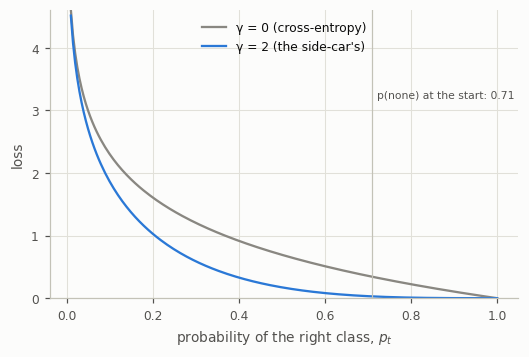

In [8]:
pt = np.linspace(0.01, 1.0, 200)
fig, ax = plt.subplots(figsize=(5.5, 3.4))
for gamma, colour in ((0, views.GREY), (2, views.CLASS_COLOURS[0])):
    ax.plot(pt, -((1 - pt) ** gamma) * np.log(pt), color=colour, label=f"γ = {gamma}" + (" (cross-entropy)" if gamma == 0 else " (the side-car's)"))
ax.axvline(0.71, color=views.AXIS, lw=0.8)
ax.text(0.72, 3.2, "p(none) at the start: 0.71", fontsize=7, color=views.INK_2)
ax.set_xlabel("probability of the right class, $p_t$")
ax.set_ylabel("loss")
ax.set_ylim(0, 4.6)
ax.legend()
plt.show()

In [9]:
idx = sidecar.hungarian(toy_out, toy_t["cls"], toy_t["box"], toy_t["mask"])
slots, tgts = idx[0]
target_cls = torch.full((1, 5), NONE)
target_cls[0, torch.as_tensor(slots)] = toy_t["cls"][0, torch.as_tensor(tgts)]
focal = sidecar.softmax_focal(toy_logits, target_cls)[0]
n = toy_t["mask"].sum().float()
print("each slot's class target:", [("none" if c == NONE else views.CLASS_NAMES[c]) for c in target_cls[0].tolist()])
print("focal per slot:", np.round(focal.numpy(), 3).tolist())
l_cls = focal.sum() / n
print(f"class term = sum / {int(n)} targets = {float(l_cls):.4f}")

each slot's class target: ['none', 'vehicle', 'pedestrian', 'none', 'none']
focal per slot: [1.2869999408721924, 0.004000000189989805, 0.04399999976158142, 0.0020000000949949026, 0.6000000238418579]
class term = sum / 2 targets = 0.9686


**Box.** Each matched slot against its target in 8 numbers: the centre in metres, the size as logs (a 10%
size error costs the same for a bus as for a pedestrian), and the yaw as sin and cos (no jump at ±180°).
L1, summed over the 8, divided by the number of targets. The transform (`sidecar.box_targets`):

In [10]:
box8 = sidecar.box_targets(toy_t["box"])
pd.DataFrame(box8[0, :2].numpy(), columns=["x", "y", "z", "log l", "log w", "log h", "sin yaw", "cos yaw"],
             index=names)

,x,y,z,log l,log w,log h,sin yaw,cos yaw
target 0: pedestrian,8.0,-3.0,0.9,-0.357,-0.357,0.588,1.0,-0.029
target 1: vehicle,12.0,0.0,0.8,1.504,0.642,0.470,0.1,0.995


In [11]:
toy_out["box"][0, 1, 3:] = torch.tensor([1.4, 0.6, 0.5, 0.0, 1.0])  # slot 1's size and yaw
toy_out["vel"][0, 1] = torch.tensor([4.0, 0.0])
toy_out["path"][0, 1] = torch.tensor([[2.0, 0.0], [4.0, 0.0]])
toy_out["path"][0, 2] = torch.tensor([[0.0, 0.5], [0.0, 1.0]])
pi, ti = torch.as_tensor(slots), torch.as_tensor(tgts)
l_box = (toy_out["box"][0, pi] - box8[0, ti]).abs().sum() / n
l_vel = (toy_out["vel"][0, pi] - toy_t["vel"][0, ti]).abs().sum() / n
ok = toy_t["path_ok"][0, ti][..., None].float()
n_path = toy_t["path_ok"].sum().clamp(min=1).float()
l_path = ((toy_out["path"][0, pi] - toy_t["path"][0, ti]).abs() * ok).sum() / n_path
by_hand = 2 * l_cls + 0.25 * l_box + 0.25 * l_vel + 0.25 * l_path
loss, parts = sidecar.SideCarLoss()([toy_out], toy_t)
pd.DataFrame(
    {"by hand": [float(l_cls), float(l_box), float(l_vel), float(l_path), float(by_hand)],
     "SideCarLoss": [parts["cls0"], parts["box0"], parts["vel0"], parts["path0"], float(loss)],
     "weight": [2, 0.25, 0.25, 0.25, ""]},
    index=["class (focal, / targets)", "box (L1 of 8, / targets)", "velocity (L1, / targets)",
           f"path (L1 where the track lasted, / {int(n_path)} valid steps)", "total"],
)

,by hand,SideCarLoss,weight
"class (focal, / targets)",0.969,0.969,2
"box (L1 of 8, / targets)",2.555,2.555,0.25
"velocity (L1, / targets)",1.200,1.200,0.25
"path (L1 where the track lasted, / 3 valid steps)",0.767,0.767,0.25
total,3.068,3.068,


In [12]:
assert abs(float(loss) - float(by_hand)) < 1e-5
print("the loss built by hand equals SideCarLoss's on the toy")

the loss built by hand equals SideCarLoss's on the toy


**Two details the toy shows.**
- The pedestrian's +1.0 s step is unknown (its track ended), so that step adds nothing and is not counted
  in the path term's denominator: **the path term divides by valid steps (3 here), the others by
  targets (2)**. Per target, the path term weighs about half of what its 0.25 suggests.
- The box term mixes units: three centre numbers in metres, five unitless. Once sizes and yaw are learnt,
  it is mostly a centre-distance loss.

The whole loss is the sum of this over the **three** layers, each matched on its own.

## 5. The loss on a real batch, before any training

Sixteen train samples (seeded), v1 at seed 0, exactly as step 0 of a run sees them (fp32 here; the run uses
fp16 autocast for the forward).

In [13]:
picked = np.random.default_rng(5).choice(rows["train"], 16, replace=False)
batch = batch_of(picked)
torch.manual_seed(0)
model = train_sidecar.build_model({"tap": "vit_out", **train_sidecar.VARIANTS["v1"]})
model.train()
torch.manual_seed(0)
outs = model(batch["tokens"], batch["projection"])
loss, parts = sidecar.SideCarLoss()(outs, batch)
print(f"{int(batch['mask'].sum())} targets in 16 samples; total loss {float(loss):.2f}")
weights = {"cls": 2, "box": 0.25, "vel": 0.25, "path": 0.25}
start = pd.DataFrame({f"layer {l}": {term: parts[f"{term}{l}"] for term in weights} for l in range(3)})
start["weight"] = pd.Series(weights)
start.loc["weighted sum"] = [sum(weights[t] * parts[f"{t}{l}"] for t in weights) for l in range(3)] + [""]
start

99 targets in 16 samples; total loss 25.61


,layer 0,layer 1,layer 2,weight
cls,2.187,2.367,2.417,2.0
box,11.444,11.544,11.311,0.25
vel,2.197,2.299,2.222,0.25
path,1.826,1.932,1.888,0.25
weighted sum,8.240,8.678,8.690,


**Reading it.** At the start every slot says "none" with p ≈ 0.71, so the class term is mostly the targets'
slots, each costing −(1 − 0.097)² log 0.097 ≈ 1.9, plus 0.03 for each of the other slots, divided by the
targets: 1.9 × 99 + 0.03 × 925, over 99 targets, is 2.2, as measured for layer 0. The box term is several
metres of centre error per target: each target is matched to the nearest reference point, and the
references are spread over 2,880 m². Every layer starts at the same centres (Δcentre is zero-initialised),
so the three layers' box terms are almost equal at step 0; their class terms differ because each layer's
class head starts from its own random weights.

Which of the box term's 8 numbers carry it:

In [14]:
idx = sidecar.hungarian(outs[-1], batch["cls"], batch["box"], batch["mask"])
bi = torch.cat([torch.full((len(i),), b) for b, (i, _) in enumerate(idx)])
pi = torch.cat([torch.as_tensor(i) for i, _ in idx])
ti = torch.cat([torch.as_tensor(j) for _, j in idx])
err = (outs[-1]["box"][bi, pi] - sidecar.box_targets(batch["box"])[bi, ti]).abs().detach().numpy()
pd.Series(err.mean(0), index=["x", "y", "z", "log l", "log w", "log h", "sin yaw", "cos yaw"], name="mean |error| per target, last layer").to_frame().T

,x,y,z,log l,log w,log h,sin yaw,cos yaw
"mean |error| per target, last layer",2.789,4.879,0.732,0.758,0.468,0.474,0.401,0.809


**The matching at step 0, for one sample:** each target (class colour) joined to the slot it was matched
to, at that slot's centre (its reference point).

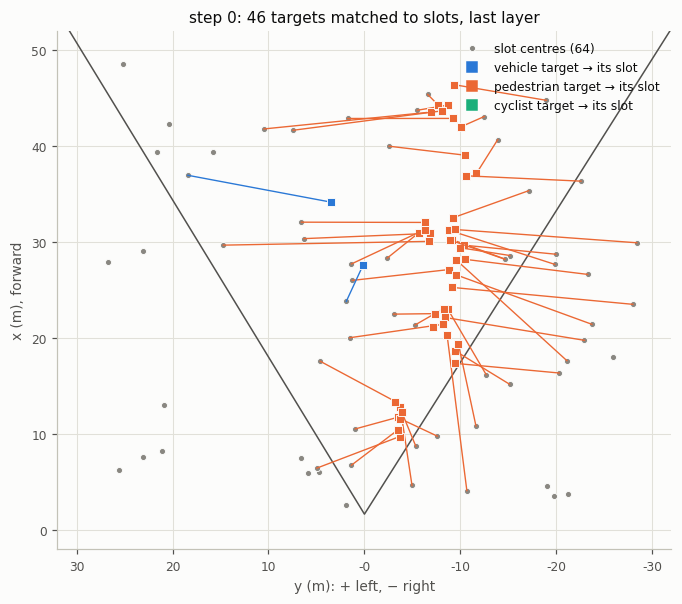

In [15]:
b = int(np.argmax([len(j) for _, j in idx]))
i_b, j_b = idx[b]
t_b = {k: v[b].numpy() for k, v in batch.items() if k not in ("tokens", "projection")}
centres = outs[-1]["box"][b, :, :2].detach().numpy()
fig, ax = plt.subplots(figsize=(7.2, 6.2))
edges = views.view_edges(batch["projection"][b].numpy(), reach=60)
ax.plot(-edges[[1, 0, 2], 1], edges[[1, 0, 2], 0], color=views.INK_2, lw=1.0)
ax.plot(-centres[:, 1], centres[:, 0], "o", ms=4, color=views.GREY, mec=views.SURFACE, mew=0.6, label="slot centres (64)")
for q, g in zip(i_b, j_b):
    colour = views.CLASS_COLOURS[t_b["cls"][g]]
    ax.plot([-centres[q, 1], -t_b["box"][g, 1]], [centres[q, 0], t_b["box"][g, 0]], color=colour, lw=0.9)
    ax.plot(-t_b["box"][g, 1], t_b["box"][g, 0], "s", ms=5, color=colour, mec=views.SURFACE, mew=0.6)
for c, name in enumerate(views.CLASS_NAMES):
    ax.plot([], [], "s", color=views.CLASS_COLOURS[c], label=f"{name} target → its slot")
ax.set_aspect("equal")
y_axis_left(ax)
ax.set_xlim(-32, 32)
ax.set_ylim(-2, 52)
ax.legend(loc="upper right")
ax.set_title(f"step 0: {len(j_b)} targets matched to slots, last layer")
plt.show()

## 6. A short fit: does every term go down?

The same 16 samples, the run's optimiser (AdamW 2e-4, weight decay 0.01, clip 35), 300 steps on the CPU in
fp32. An illustration, not the check: the check is the trainer's own `overfit` (64 samples, until the
matched centre error is under 0.5 m and class accuracy over 95%), whose log follows.

In [16]:
torch.manual_seed(0)
model = train_sidecar.build_model({"tap": "vit_out", **train_sidecar.VARIANTS["v1"]})
optimiser = torch.optim.AdamW(model.parameters(), lr=train_sidecar.LR, weight_decay=train_sidecar.WEIGHT_DECAY)
criterion = sidecar.SideCarLoss()
history = []
model.train()
for step in range(1, 301):
    outs = model(batch["tokens"], batch["projection"])
    loss, parts = criterion(outs, batch)
    optimiser.zero_grad(set_to_none=True)
    loss.backward()
    grad_norm = float(torch.nn.utils.clip_grad_norm_(model.parameters(), train_sidecar.CLIP))
    optimiser.step()
    numbers = train_sidecar.match_numbers(outs[-1], batch, parts["_match"])
    history.append({"step": step, "loss": float(loss), "grad_norm": grad_norm, **numbers,
                    **{k: v for k, v in parts.items() if not k.startswith("_")}})
history = pd.DataFrame(history)
print(history.iloc[[0, 49, 99, 199, 299]][["step", "loss", "cls2", "box2", "vel2", "path2", "match_centre_m", "match_class_acc"]].round(3).to_string(index=False))

 step   loss  cls2   box2  vel2  path2  match_centre_m  match_class_acc
    1 25.606 2.429 11.318 2.191  1.890           6.434            0.000
   50 10.653 0.357  8.219 1.632  1.444           5.683            0.626
  100  6.245 0.043  6.259 0.858  0.763           4.420            0.949
  200  3.098 0.007  3.001 0.549  0.482           1.845            1.000
  300  1.790 0.001  1.738 0.366  0.328           0.937            1.000


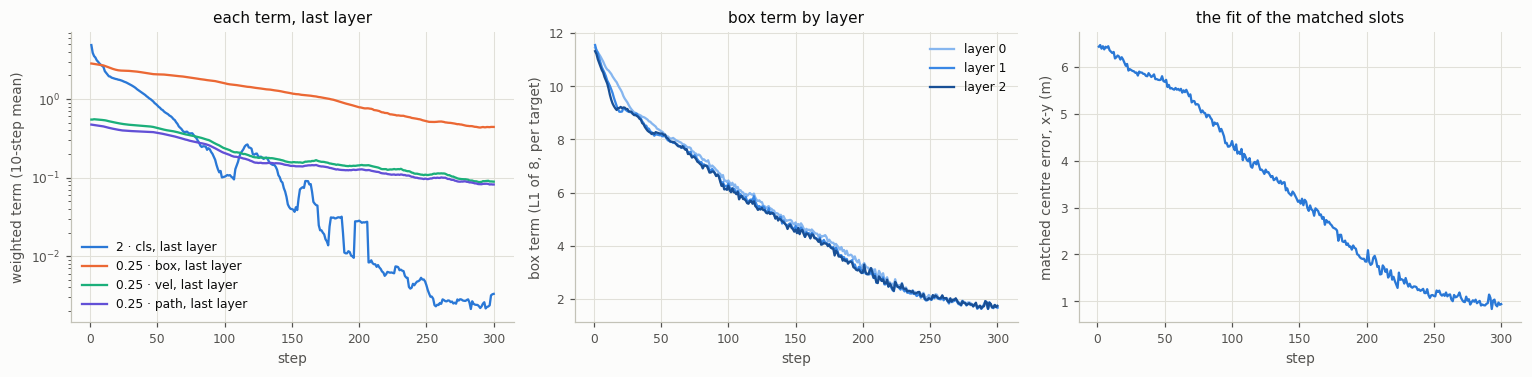

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
ax = axes[0]
for term, colour in zip(("cls", "box", "vel", "path"), ("#2a78d6", "#eb6834", "#1baf7a", "#6250d6")):
    smooth = (history[f"{term}2"] * weights[term]).rolling(10, min_periods=1).mean()
    ax.plot(history.step, smooth, color=colour, label=f"{weights[term]} · {term}, last layer")
ax.set_yscale("log")
ax.set_xlabel("step")
ax.set_ylabel("weighted term (10-step mean)")
ax.legend()
ax.set_title("each term, last layer")
ax = axes[1]
for l, colour in zip(range(3), ("#86b6ef", "#3987e5", "#184f95")):
    ax.plot(history.step, history[f"box{l}"], color=colour, label=f"layer {l}")
ax.set_xlabel("step")
ax.set_ylabel("box term (L1 of 8, per target)")
ax.legend()
ax.set_title("box term by layer")
ax = axes[2]
ax.plot(history.step, history.match_centre_m, color=views.CLASS_COLOURS[0])
ax.set_xlabel("step")
ax.set_ylabel("matched centre error, x-y (m)")
ax.set_title("the fit of the matched slots")
plt.tight_layout()
plt.show()

**The trainer's own overfit check** (`part-a-overfit`, recipe stage of step 3; on the GPU, 64 train samples,
constant learning rate): its log, as written.

['overfit check passed at step 1300']


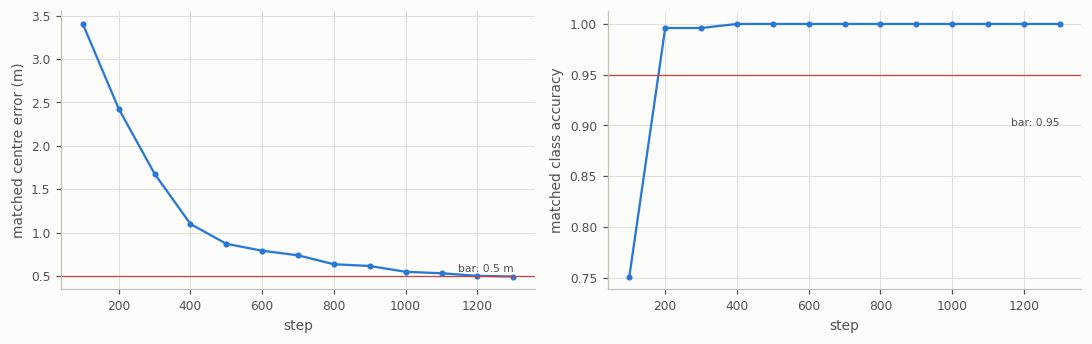

In [18]:
import re

log_lines = (RUNS / "part-a" / "r1-overfit.log").read_text().splitlines()
steps = [tuple(map(float, m.groups())) for m in (re.match(r"step (\d+): loss ([\d.]+) centre ([\d.]+) m class acc ([\d.]+)", l) for l in log_lines) if m]
overfit = pd.DataFrame(steps, columns=["step", "loss", "centre (m)", "class accuracy"])
print([l for l in log_lines if "overfit check" in l])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(overfit.step, overfit["centre (m)"], "o-", ms=3, color=views.CLASS_COLOURS[0])
axes[0].axhline(0.5, color=views.MISS, lw=0.8)
axes[0].text(overfit.step.max(), 0.55, "bar: 0.5 m", ha="right", fontsize=7, color=views.INK_2)
axes[0].set_xlabel("step")
axes[0].set_ylabel("matched centre error (m)")
axes[1].plot(overfit.step, overfit["class accuracy"], "o-", ms=3, color=views.CLASS_COLOURS[0])
axes[1].axhline(0.95, color=views.MISS, lw=0.8)
axes[1].text(overfit.step.max(), 0.9, "bar: 0.95", ha="right", fontsize=7, color=views.INK_2)
axes[1].set_xlabel("step")
axes[1].set_ylabel("matched class accuracy")
plt.tight_layout()
plt.show()

## 7. A primer: the loss options, and how each one shapes the gradient

The side-car's loss is one choice among many. For each part: the options, what each does to the gradient
that trains the network, and where it comes from. References are at the end of this section; the measured
cells use this notebook's batch and the pipeline check's run.

### 7.1 The class term

| Option | Loss, for the true class's probability p | Its gradient on that class's logit | Used by |
|---|---|---|---|
| cross-entropy | −log p | p − 1: never zero, so thousands of easy "none" slots still pull | the classic choice |
| **focal, γ = 2 (the side-car's)** | −(1 − p)^γ log p | shrunk by about (1 − p)^γ when p is near 1: easy slots go quiet, hard ones keep their pull | RetinaNet [Lin 2017]; Deformable DETR, DETR3D, PETR use its sigmoid form |
| sigmoid focal, one-vs-rest | a binary focal loss per class | classes do not compete; "none" is every class low | Deformable DETR [Zhu 2021] |
| quality / varifocal | the target is the box's quality (IoU), not 1 | confidence learns to mean "how well placed", which ranks detections better | GFL [Li 2020]; VarifocalNet [Zhang 2021] |
| label smoothing | the target is 1 − ε | caps confidence; a regulariser | [Szegedy 2016] |

How γ quiets the easy cases (the gradient's size on the true class's logit, two classes for simplicity):

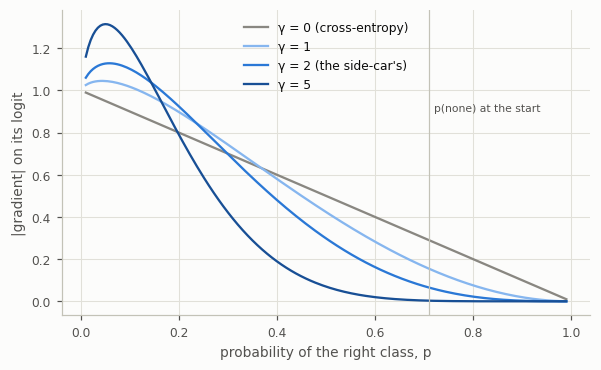

In [19]:
p = torch.linspace(0.01, 0.99, 200, requires_grad=False)
fig, ax = plt.subplots(figsize=(6.2, 3.6))
for gamma, colour in ((0, views.GREY), (1, "#86b6ef"), (2, views.CLASS_COLOURS[0]), (5, "#184f95")):
    z = torch.log(p / (1 - p)).clone().requires_grad_(True)  # the logit whose sigmoid is p
    q = torch.sigmoid(z)
    loss = (-((1 - q) ** gamma) * torch.log(q)).sum()
    (grad,) = torch.autograd.grad(loss, z)
    ax.plot(p.numpy(), grad.abs().numpy(), color=colour, label=f"γ = {gamma}" + (" (cross-entropy)" if gamma == 0 else " (the side-car's)" if gamma == 2 else ""))
ax.axvline(0.71, color=views.AXIS, lw=0.8)
ax.text(0.72, 0.9, "p(none) at the start", fontsize=7, color=views.INK_2)
ax.set_xlabel("probability of the right class, p")
ax.set_ylabel("|gradient| on its logit")
ax.legend()
plt.show()

### 7.2 The regression terms

| Option | Loss on a residual r | Its gradient | Notes |
|---|---|---|---|
| L2 | r² / 2 | r: grows with the error, so outliers (a mislabelled box, a hidden agent) dominate | |
| **L1 (the side-car's)** | \|r\| | ±1: every residual pulls the same; robust; learns the median | DETR's box loss [Carion 2020] |
| smooth L1 / Huber, δ | quadratic below δ, linear above | r below δ, ±1 above: fine near the answer, robust far from it | Fast R-CNN [Girshick 2015] |
| Laplace likelihood with a learnt scale b | \|r\| / b + log b | ±1 / b: a target the network finds hopeless (far, hidden) gets a large b and stops pulling; b is a calibrated "how sure" | [Kendall & Gal 2017]; KL-Loss [He 2019] |
| IoU family: GIoU, DIoU, 3D or rotated IoU | 1 − IoU (+ a penalty) | scale-free; couples centre, size and yaw | [Rezatofighi 2019]; [Zheng 2020] |
| disentangled | each group (centre, size, yaw) scored with the others set to the truth | one group's error cannot hide behind another's | MonoDIS [Simonelli 2019] |

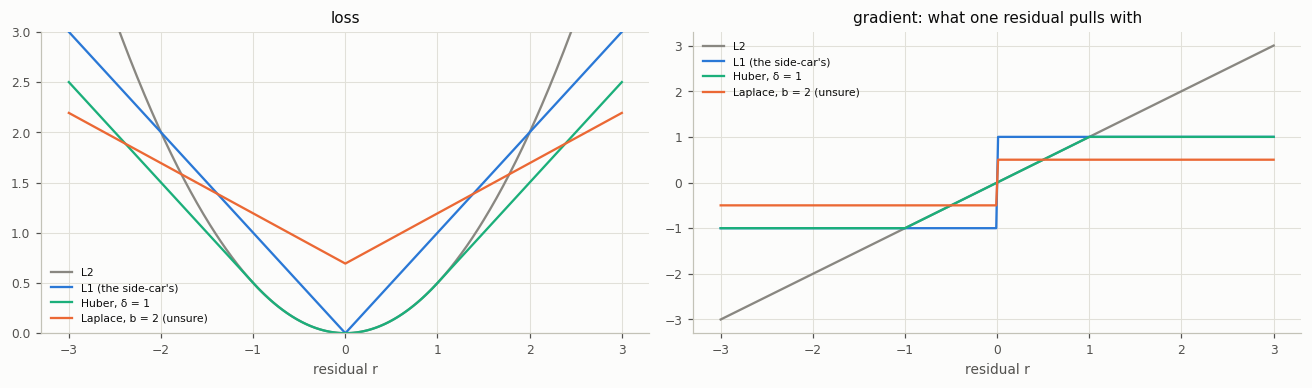

In [20]:
r = np.linspace(-3, 3, 601)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
curves = {
    "L2": (r**2 / 2, r),
    "L1 (the side-car's)": (np.abs(r), np.sign(r)),
    "Huber, δ = 1": (np.where(np.abs(r) < 1, r**2 / 2, np.abs(r) - 0.5), np.clip(r, -1, 1)),
    "Laplace, b = 2 (unsure)": (np.abs(r) / 2 + np.log(2), np.sign(r) / 2),
}
for (name, (loss, grad)), colour in zip(curves.items(), (views.GREY, views.CLASS_COLOURS[0], views.CLASS_COLOURS[2], views.CLASS_COLOURS[1])):
    axes[0].plot(r, loss, color=colour, label=name)
    axes[1].plot(r, grad, color=colour, label=name)
axes[0].set_ylim(0, 3)
axes[0].set_title("loss")
axes[1].set_title("gradient: what one residual pulls with")
for ax in axes:
    ax.set_xlabel("residual r")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

### 7.3 Yaw, size, depth

- **Yaw**: sin and cos with L1 (the side-car's) avoids the jump at ±180°. MultiBin (bins + a residual) copes
  with shapes that look alike front and back [Mousavian 2017]. For pedestrians yaw means little (notebook 04
  §4b measures 72° of error against 7° for vehicles), so its term mostly adds noise for them.
- **Size**: log-size with L1 (the side-car's) makes the error relative: 10% off costs the same for a bus as for
  a pedestrian.
- **Depth**: camera-only detectors often regress depth or log-depth with an uncertainty [FCOS3D: Wang 2021];
  the side-car regresses the centre's x, y, z directly, refined layer by layer.

### 7.4 Paths

- **L1 on each future point** (the side-car's: offsets at +0.5 s and +1.0 s). One mode: for an agent that
  may turn or go on, it learns the median, in between.
- **Several modes, winner-takes-all**: only the mode closest to the truth gets the gradient, and a score
  learns which mode is likely [Guzman-Rivera 2012; Lee 2016]. A mode that never wins never trains (§8).
- **A Gaussian mixture's likelihood**: every mode gets gradient, weighted by its responsibility
  [MultiPath: Chai 2019].

### 7.5 Matching

- **Hungarian, one-to-one** (DETR's; the side-car's): each target trains exactly one slot, duplicates are
  pushed to "none". It is not differentiable: it only decides which residuals carry gradient.
- **Extra one-to-many matching in training** [H-DETR: Jia 2023; Group DETR: Chen 2023]: more positives
  per target, faster convergence, the same model at inference.
- **Denoising queries** [DN-DETR: Li 2022]: noisy copies of the targets fed as extra queries; steadies the
  matching early in training.

### 7.6 Combining the terms

| Method | What it is | What it does to the update |
|---|---|---|
| **fixed weighted sum (the side-car's: 2, 0.25, 0.25, 0.25)** | L = Σ wᵢ Lᵢ | each term's gradient scaled by a hand-set wᵢ |
| **normalisation** (the side-car divides by the batch's targets) | per-target averages | the same gradient scale for any batch |
| uncertainty weighting | L = Σ Lᵢ / (2σᵢ²) + log σᵢ, σᵢ learnt [Kendall, Gal & Cipolla 2018] | at its optimum each term is weighted about 1 / (2Lᵢ): large or noisy terms count less |
| GradNorm | weights learnt so each term's gradient on the shared layers grows at the same rate [Chen 2018] | balances by gradient size, not by loss size |
| dynamic weight averaging | weights from each loss's recent rate of descent [Liu 2019] | slow-falling terms gain weight |
| PCGrad | where two terms' gradients conflict, each is projected off the other [Yu 2020] | no tug-of-war on shared parameters |
| MGDA | the smallest-norm combination that lowers every term [Sener & Koltun 2018] | a Pareto-stationary point |

**What uncertainty weighting would make of the side-car's terms.** Its weights settle at about 1 / (2Lᵢ).
Read with the per-term losses at the end of the pipeline check's epoch (last 50 steps, last layer):

In [21]:
RUN = RUNS / "part-a" / "r1-pipeline-v1-s0"
last = json.loads((RUN / "steps.jsonl").read_text().splitlines()[-1])
measured = {term: last[f"{term}2"] for term in weights}
implied = {term: 1 / (2 * value) for term, value in measured.items()}
scale = sum(weights.values()) / sum(implied.values())  # same total, to compare shares
pd.DataFrame({
    "loss, last 50 steps (last layer)": measured,
    "fixed weight (the side-car's)": weights,
    "weighted loss now": {t: weights[t] * measured[t] for t in weights},
    "uncertainty weighting's weight (rescaled)": {t: implied[t] * scale for t in weights},
}).round(3)

,"loss, last 50 steps (last layer)",fixed weight (the side-car's),weighted loss now,uncertainty weighting's weight (rescaled)
cls,0.676,2.00,1.352,1.062
box,3.736,0.25,0.934,0.192
vel,1.095,0.25,0.274,0.656
path,0.855,0.25,0.214,0.840


**Read:**
- Under the fixed weights, the class term is the largest weighted term, then the box term.
- Uncertainty weighting would roughly halve the class term's weight and cut the box term's by a quarter.
  It would multiply velocity's by about 2.6 and path's by about 3.4: it shifts the effort towards motion.
- Neither is right a priori. A change of weighting would be a run of its own, chosen on select (plan §5).

### 7.7 Regularisation

| Term | What it does | In the side-car |
|---|---|---|
| weight decay, decoupled (AdamW) [Loshchilov & Hutter 2019] | shrinks every weight a little each step | 0.01, every parameter |
| dropout | zeroes activations at random | 0.1 in attention and FFN |
| gradient clipping | caps the update's size | 35: 16 of 1,471 steps clipped in epoch 1, all early |
| label smoothing | caps confidence | no |
| weight averaging (EMA) | averages the weights over steps | no |
| auxiliary losses | supervises every layer | yes, every decoder layer |
| consistency | e.g. a mirrored scene must give mirrored outputs | no: needs a mirrored token cache (plan §4.6) |

### 7.8 How the loss flows into the larger network

- **The ViT is frozen and its output cached**, so no gradient leaves the side-car: Part A cannot change the
  tokens the planner reads, whatever its loss.
- **Inside the side-car**, each term reaches every layer through its own heads (deep supervision), and the
  detached references stop a layer's box loss from pushing the layer before it.
- **If the encoder were ever trained with it** (B3's shared LoRA), the side-car's loss would change the
  planner's tokens: then its weight against the planner's losses, or a separate branch (as B3.1's was), decides
  who wins on the shared layers.

**Which parts each term trains, measured.** The same 16 samples, v1 at seed 0, step 0: each term's gradient
norm on each part of the model, backpropagated alone.

the four terms rebuilt here sum to SideCarLoss's total on the same forward: 25.6080


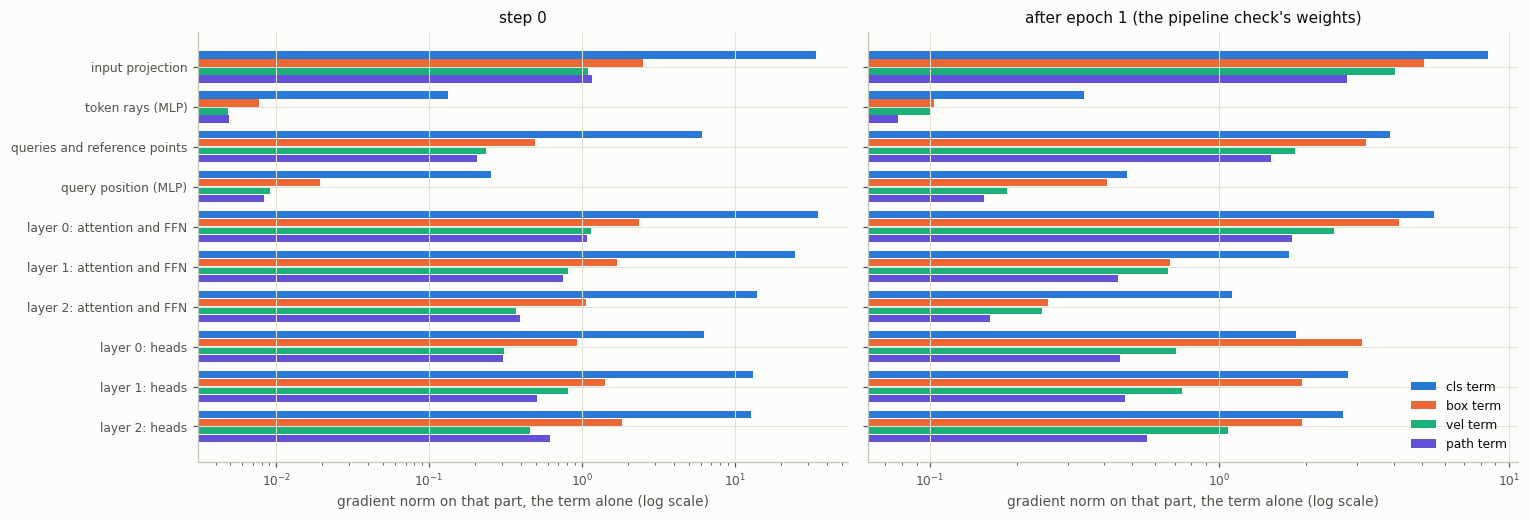

,cls,box,vel,path
"on the shared layers, relative to the box term",,,,
step 0,14.04,1.0,0.45,0.44
after epoch 1,1.65,1.0,0.73,0.51


In [22]:
def loss_terms(outs, batch):
    """The four weighted terms of SideCarLoss, summed over layers, kept as tensors (sidecar.SideCarLoss)."""
    cls, box, vel, mask = batch["cls"], batch["box"], batch["vel"], batch["mask"]
    n = mask.sum().clamp(min=1).float()
    n_path = batch["path_ok"].sum().clamp(min=1).float()
    box8 = sidecar.box_targets(box)
    terms = {"cls": 0.0, "box": 0.0, "vel": 0.0, "path": 0.0}
    for out in outs:
        idx = sidecar.hungarian(out, cls, box, mask)
        bi = torch.cat([torch.full((len(i),), b, dtype=torch.long) for b, (i, _) in enumerate(idx)])
        pi = torch.cat([torch.as_tensor(i, dtype=torch.long) for i, _ in idx])
        ti = torch.cat([torch.as_tensor(j, dtype=torch.long) for _, j in idx])
        target = torch.full(out["logits"].shape[:2], tg.NONE, dtype=torch.long)
        target[bi, pi] = cls[bi, ti]
        ok = batch["path_ok"][bi, ti][..., None].float()
        terms["cls"] = terms["cls"] + 2.0 * sidecar.softmax_focal(out["logits"], target).sum() / n
        terms["box"] = terms["box"] + 0.25 * (out["box"][bi, pi] - box8[bi, ti]).abs().sum() / n
        terms["vel"] = terms["vel"] + 0.25 * (out["vel"][bi, pi] - vel[bi, ti]).abs().sum() / n
        terms["path"] = terms["path"] + 0.25 * ((out["path"][bi, pi] - batch["path"][bi, ti]).abs() * ok).sum() / n_path
    return terms


torch.manual_seed(0)
fresh = train_sidecar.build_model({"tap": "vit_out", **train_sidecar.VARIANTS["v1"]})
fresh.train()
torch.manual_seed(0)
outs_fresh = fresh(batch["tokens"], batch["projection"])
terms = loss_terms(outs_fresh, batch)
total, _ = sidecar.SideCarLoss()(outs_fresh, batch)
assert abs(float(sum(terms.values())) - float(total)) < 1e-3, (float(sum(terms.values())), float(total))
print(f"the four terms rebuilt here sum to SideCarLoss's total on the same forward: {float(total):.4f}")
groups_of = {
    "input projection": [fresh.proj, fresh.ln_tok],
    "token rays (MLP)": [fresh.ray_mlp],
    "queries and reference points": [],
    "query position (MLP)": [fresh.pos_mlp],
    **{f"layer {l}: attention and FFN": [m.sa, m.ca, m.ffn, m.ln_sa, m.ln_ca, m.ln_ff] for l, m in enumerate(fresh.layers)},
    **{f"layer {l}: heads": [m.cls_head, m.ref_mlp, m.box_head, m.vel_head, m.path_head] for l, m in enumerate(fresh.layers)},
}
def part_groups(model):
    return {
        "input projection": [model.proj, model.ln_tok],
        "token rays (MLP)": [model.ray_mlp],
        "queries and reference points": [],
        "query position (MLP)": [model.pos_mlp],
        **{f"layer {l}: attention and FFN": [m.sa, m.ca, m.ffn, m.ln_sa, m.ln_ca, m.ln_ff] for l, m in enumerate(model.layers)},
        **{f"layer {l}: heads": [m.cls_head, m.ref_mlp, m.box_head, m.vel_head, m.path_head] for l, m in enumerate(model.layers)},
    }


def term_gradients(model, outs):
    """Each term's gradient norm on each part of `model`, the term backpropagated alone."""
    found = {}
    for term, value in loss_terms(outs, batch).items():
        model.zero_grad(set_to_none=True)
        value.backward(retain_graph=True)
        row = {}
        for name, modules in part_groups(model).items():
            params = [p for m in modules for p in m.parameters()] if modules else [model.query, model.ref]
            row[name] = float(torch.sqrt(sum((p.grad**2).sum() for p in params if p.grad is not None)))
        found[term] = row
    return pd.DataFrame(found)


at_start = term_gradients(fresh, outs_fresh)
after_one, _ = train_sidecar.load_run(RUNS / "part-a" / "r1-pipeline-v1-s0")
after_one.train()
torch.manual_seed(0)
at_epoch_1 = term_gradients(after_one, after_one(batch["tokens"], batch["projection"]))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, norms, title in ((axes[0], at_start, "step 0"), (axes[1], at_epoch_1, "after epoch 1 (the pipeline check's weights)")):
    y = np.arange(len(norms))
    for i, (term, colour) in enumerate(zip(norms.columns, ("#2a78d6", "#eb6834", "#1baf7a", "#6250d6"))):
        ax.barh(y + (i - 1.5) * 0.2, norms[term].values, height=0.18, color=colour, label=f"{term} term")
    ax.set_yticks(y)
    ax.set_yticklabels(norms.index)
    ax.set_xscale("log")
    ax.set_xlabel("gradient norm on that part, the term alone (log scale)")
    ax.set_title(title)
axes[0].invert_yaxis()
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()
shared = [n for n in at_start.index if "attention" in n or n == "input projection"]
pd.DataFrame({"step 0": at_start.loc[shared].sum() / at_start.loc[shared].sum()["box"],
              "after epoch 1": at_epoch_1.loc[shared].sum() / at_epoch_1.loc[shared].sum()["box"]},
             ).T.round(2).rename_axis("on the shared layers, relative to the box term")

**Read:**
- Every term reaches every shared part, so the weights decide how the shared layers are pulled.
- **At step 0 the class term's gradient on them is about 14 times the box term's; after epoch 1, 1.65
  times.** Its gradient flows through all 64 slots, not only the matched ones. It dominates while every
  slot is unsure, and quiets as they grow confident, which is what the focal term is for.
- **The token-ray MLP gets almost no gradient from any term**, about two orders of magnitude below the
  attention layers. That fits notebook 02b §1: one epoch in, the side-car does not use the rays
  geometrically.

### References

- [Carion 2020] N. Carion et al., *End-to-End Object Detection with Transformers* (DETR), ECCV 2020.
- [Zhu 2021] X. Zhu et al., *Deformable DETR: Deformable Transformers for End-to-End Object Detection*, ICLR 2021.
- [Li 2022] F. Li et al., *DN-DETR: Accelerate DETR Training by Introducing Query DeNoising*, CVPR 2022.
- [Jia 2023] D. Jia et al., *DETRs with Hybrid Matching* (H-DETR), CVPR 2023.
- [Chen 2023] Q. Chen et al., *Group DETR: Fast DETR Training with Group-Wise One-to-Many Assignment*, ICCV 2023.
- [Lin 2017] T.-Y. Lin et al., *Focal Loss for Dense Object Detection*, ICCV 2017.
- [Li 2020] X. Li et al., *Generalized Focal Loss*, NeurIPS 2020.
- [Zhang 2021] H. Zhang et al., *VarifocalNet: An IoU-aware Dense Object Detector*, CVPR 2021.
- [Szegedy 2016] C. Szegedy et al., *Rethinking the Inception Architecture for Computer Vision* (label smoothing), CVPR 2016.
- [Girshick 2015] R. Girshick, *Fast R-CNN* (smooth L1), ICCV 2015.
- [Kendall & Gal 2017] A. Kendall and Y. Gal, *What Uncertainties Do We Need in Bayesian Deep Learning for Computer Vision?*, NeurIPS 2017.
- [He 2019] Y. He et al., *Bounding Box Regression with Uncertainty for Accurate Object Detection* (KL-Loss), CVPR 2019.
- [Rezatofighi 2019] H. Rezatofighi et al., *Generalized Intersection over Union*, CVPR 2019.
- [Zheng 2020] Z. Zheng et al., *Distance-IoU Loss*, AAAI 2020.
- [Simonelli 2019] A. Simonelli et al., *Disentangling Monocular 3D Object Detection* (MonoDIS), ICCV 2019.
- [Mousavian 2017] A. Mousavian et al., *3D Bounding Box Estimation Using Deep Learning and Geometry* (MultiBin), CVPR 2017.
- [Wang 2021] T. Wang et al., *FCOS3D: Fully Convolutional One-Stage Monocular 3D Object Detection*, ICCV Workshops 2021.
- [Guzman-Rivera 2012] A. Guzman-Rivera, D. Batra and P. Kohli, *Multiple Choice Learning*, NeurIPS 2012.
- [Lee 2016] S. Lee et al., *Stochastic Multiple Choice Learning for Training Diverse Deep Ensembles*, NeurIPS 2016.
- [Chai 2019] Y. Chai et al., *MultiPath: Multiple Probabilistic Anchor Trajectory Hypotheses for Behavior Prediction*, CoRL 2019.
- [Kendall, Gal & Cipolla 2018] A. Kendall, Y. Gal and R. Cipolla, *Multi-Task Learning Using Uncertainty to Weigh Losses*, CVPR 2018.
- [Chen 2018] Z. Chen et al., *GradNorm: Gradient Normalization for Adaptive Loss Balancing*, ICML 2018.
- [Liu 2019] S. Liu, E. Johns and A. Davison, *End-to-End Multi-Task Learning with Attention* (dynamic weight averaging), CVPR 2019.
- [Yu 2020] T. Yu et al., *Gradient Surgery for Multi-Task Learning* (PCGrad), NeurIPS 2020.
- [Sener & Koltun 2018] O. Sener and V. Koltun, *Multi-Task Learning as Multi-Objective Optimization* (MGDA), NeurIPS 2018.
- [Loshchilov & Hutter 2019] I. Loshchilov and F. Hutter, *Decoupled Weight Decay Regularization* (AdamW), ICLR 2019.

## 8. Does this model have a mode-collapse problem?

"Mode collapse" means different things in different models. Three could apply here:

1. **Query collapse**, DETR's version: many slots predict the same agent (duplicates), or nearly every slot
   settles on "none" and the model under-detects. One-to-one matching (each target trains one slot, the rest
   learn "none") and self-attention among slots (notebook 02b §2) are what prevent it.
2. **Representation collapse**: every input mapped to the same embedding, the failure JEPA-style
   self-supervised encoders guard against. Not a risk here: the encoder is frozen, and the side-car learns
   from labels.
3. **Trajectory mode collapse**: a multi-mode path head whose modes all become one, or where some never win.
   The side-car's path head has one mode, so it cannot collapse; its failure is the opposite, averaging: for
   an agent that may turn or go on, it predicts in between.

The checks for (1) on the pipeline check's checkpoint, on the select logs:

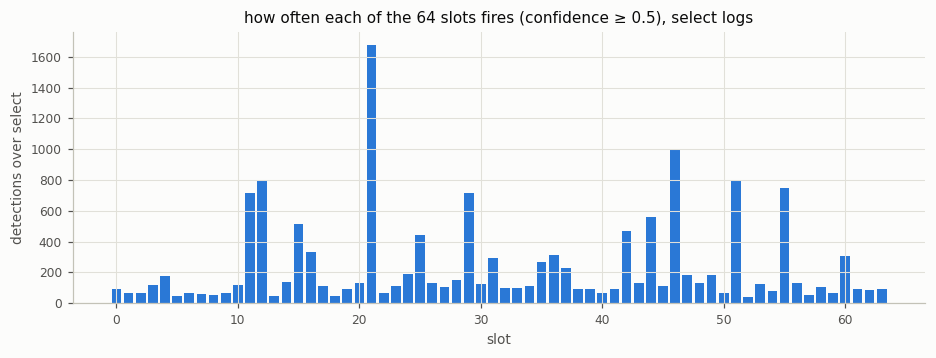

,"the pipeline check's checkpoint, select"
slots that ever fire,64 of 64
share of all detections made by the busiest 8 slots,0.471
detections per sample,3.337
targets per sample,7.264
"duplicate pairs (same class, within 2 m) per sample",0.993
share of detections with a same-class detection within 2 m,0.261


In [23]:
car, kept = train_sidecar.load_run(RUN)
dev = torch.device("cuda", int(np.argmax([torch.cuda.mem_get_info(i)[0] for i in range(torch.cuda.device_count())]))) if torch.cuda.is_available() else torch.device("cpu")
car = car.to(dev).eval()
select = rows["select"]
logits_all, centres_all = [], []
with torch.no_grad(), torch.autocast(dev.type, dtype=torch.float16, enabled=dev.type == "cuda"):
    for i in range(0, len(select), 128):
        chunk = select[i : i + 128]
        tok = torch.from_numpy(np.stack([np.asarray(vit[r], dtype=np.float16) for r in chunk])).to(dev)
        o = car(tok if dev.type == "cuda" else tok.float(), torch.from_numpy(proj[chunk]).to(dev))[-1]
        logits_all.append(o["logits"].float().cpu().numpy())
        centres_all.append(o["box"][..., :3].float().cpu().numpy())
logits_all, centres_all = np.concatenate(logits_all), np.concatenate(centres_all)
probs = np.exp(logits_all - logits_all.max(-1, keepdims=True))
probs /= probs.sum(-1, keepdims=True)
conf_all, cls_all = 1 - probs[..., tg.NONE], probs[..., : tg.NONE].argmax(-1)
detected = conf_all >= 0.5
per_slot = detected.sum(0)
duplicates, in_duplicate = 0, 0
for i in range(len(select)):
    q = np.flatnonzero(detected[i])
    close = np.zeros(len(q), bool)
    for ai in range(len(q)):
        for bi in range(ai + 1, len(q)):
            a_, b_ = q[ai], q[bi]
            if cls_all[i, a_] == cls_all[i, b_] and np.hypot(*(centres_all[i, a_, :2] - centres_all[i, b_, :2])) <= 2.0:
                duplicates += 1
                close[ai] = close[bi] = True
    in_duplicate += int(close.sum())
n_targets = np.mean([targets_of(r)["mask"].sum() for r in select])
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(np.arange(len(per_slot)), per_slot, width=0.8, color=views.CLASS_COLOURS[0])
ax.set_xlabel("slot")
ax.set_ylabel("detections over select")
ax.set_title("how often each of the 64 slots fires (confidence ≥ 0.5), select logs")
plt.show()
pd.Series({
    "slots that ever fire": f"{int((per_slot > 0).sum())} of {len(per_slot)}",
    "share of all detections made by the busiest 8 slots": float(np.sort(per_slot)[-8:].sum() / per_slot.sum()),
    "detections per sample": float(detected.sum(1).mean()),
    "targets per sample": float(n_targets),
    "duplicate pairs (same class, within 2 m) per sample": duplicates / len(select),
    "share of detections with a same-class detection within 2 m": in_duplicate / max(int(detected.sum()), 1),
}, name="the pipeline check's checkpoint, select").to_frame()

**Reading it** (epoch 1 of 12): **two of the three signs show, at this early point.**
- **Under-detection:** 3.3 detections a sample against 7.3 targets.
- **Duplicates:** about one pair of same-class detections within 2 m per sample, and a quarter of all
  detections have such a twin. Self-attention has not yet taught the slots to split the agents (notebook
  02b §2).
- **Not concentration:** every one of the 64 slots fires, though the busiest 8 make about half of all
  detections.

**What to do about it:** a converged DETR-style decoder should lose both, and step 5's curves must show it.
So the plan (§5) adds these numbers to every epoch's select record: detections per sample, duplicate pairs,
and slot use. That is a small addition to the readout, made at step 5. Persistent duplicates would point at
the remedies in §7.5 (one-to-many matching, denoising queries); persistent under-detection, at the class
term's weight (§7.6).

## 9. Weighting what matters: the loss-side options (proposals)

Notebook 01 §8 derives, from the labels, which targets are **visible** (line of sight), **causal** (visible
and in or near the ego's path), and which pedestrians form **groups**. The loss could use them; v1 does not.
The options, and what each does to the gradient:

| Option | The change | What carries gradient then |
|---|---|---|
| causal weights | each matched target's box, velocity and path terms (and its slot's class term) weighted: 1 if causal, λ if visible but not causal, λₕ if hidden | causal targets pull hardest; hidden ones barely |
| ignore regions | a slot matched to a hidden, non-causal target is not pushed to "none", and that target is not a miss | the side-car is neither rewarded nor punished for agents it cannot see |
| pedestrian groups | one target per group (its nearest member); the other members become ignore regions | one detection per group is enough; three on a crowd are not punished as false |
| nearest first | weights falling with rank or distance | near agents pull hardest |

What the causal targets carry today, on this notebook's batch of 16 (step 0, the last layer's matching):

In [24]:
from gallops.drivejepa_perception import importance as im
from gallops.drivejepa_perception.geometry import EGO_WIDTH

fresh.eval()  # one deterministic forward (no dropout) for the matching and the residuals
with torch.no_grad():
    last_out = fresh(batch["tokens"], batch["projection"])[-1]
idx = sidecar.hungarian(last_out, batch["cls"], batch["box"], batch["mask"])
box_err, is_causal, is_visible = [], [], []
for b, (slots_b, targets_b) in enumerate(idx):
    row = int(picked[b])
    lab = im.target_importance(navsim_data.agents_of(labels, row), proj[row], labels["ego_future"][row], ego_half_width=EGO_WIDTH / 2)
    err = (last_out["box"][b, torch.as_tensor(slots_b)] - sidecar.box_targets(batch["box"])[b, torch.as_tensor(targets_b)]).abs().sum(-1)
    box_err += err.tolist()
    is_causal += lab["causal"][targets_b].tolist()
    is_visible += (np.nan_to_num(lab["visible"][targets_b]) >= im.VISIBLE_MIN).tolist()
box_err, is_causal, is_visible = np.array(box_err), np.array(is_causal), np.array(is_visible)
weights_now = np.ones_like(box_err)
weights_new = np.where(is_causal, 1.0, np.where(is_visible, 0.3, 0.1))
pd.DataFrame({
    "share of targets": [is_causal.mean(), (is_visible & ~is_causal).mean(), (~is_visible).mean()],
    "share of the box term now": [(box_err * weights_now)[m].sum() / (box_err * weights_now).sum() for m in (is_causal, is_visible & ~is_causal, ~is_visible)],
    "with weights 1 / 0.3 / 0.1": [(box_err * weights_new)[m].sum() / (box_err * weights_new).sum() for m in (is_causal, is_visible & ~is_causal, ~is_visible)],
}, index=["causal", "visible, not causal", "hidden"]).round(3)

,share of targets,share of the box term now,with weights 1 / 0.3 / 0.1
causal,0.020,0.013,0.074
"visible, not causal",0.384,0.329,0.556
hidden,0.596,0.658,0.370


**Read:**
- **Today, most of the box term comes from agents the camera can barely see:** on this batch, at step 0,
  hidden targets are 60% of the targets and carry 66% of the box term. L1's gradient has the same size for
  every target, so their share of the box gradient is their share of the targets, 60%.
- The causal targets carry about their share, 1.3%.
- The illustrative weights (1, 0.3, 0.1) would raise the causal share about six-fold and cut the hidden
  targets' share to about a third.

Which weights to use, and whether to weight at all, is a choice for the review (plan §11.9). Its run would
be read on **causal recall**, defined in notebook 04 §4e.

## Summary for the review

1. **The loss is what the plan says it is**: the matching and every term, built by hand, equal
   `SideCarLoss` to 1e-5 on the toy.
2. **Matching trades 8 m of distance against full class certainty.** At the start, when every slot says
   "none", matching is by distance to the reference points.
3. **About half of the reference points start outside the camera's view** (counted above for v1 and v2).
   They are not stuck (the first layer's Δcentre is unbounded), but they start with no prior; v1 keeps
   this to stay comparable with the first pass.
4. **The box term is mostly centre distance in metres**, and the path term divides by valid steps, not
   targets: two weightings the plan records rather than changes (§5).
5. **Every term falls on a fixed batch.** The class term goes first (class accuracy 1.00 by step 200),
   the box term follows. The later layers sit only slightly below the first in so short a fit; whether
   they earn their keep on real data is read from the runs' per-layer curves (notebook 03). The trainer's
   own overfit check passed at step 1,300 of 4,000 (centre 0.49 m, class accuracy 1.00).